# Otimização de Portfólio via Método de Barreira Logarítmica
### **COS360 — Otimização (UFRJ)** | Caderno de Estudo & Referência

Este notebook foi estruturado com **foco total na formulação e nos algoritmos de otimização** (~80% do conteúdo), mantendo o contexto financeiro apenas como caso de teste numérico limpo para a disciplina:

1. **Dados e Cenários (1 slide na apresentação):** $N = 20$ ações da cadeia ampliada do agronegócio brasileiro (2015–2024, $T = 120$ meses) para gerar o vetor $\mu$ e a matriz $\Sigma$, em duas versões de pesos de cenários $p_t$ (Base $1/T$ vs. Climático via Kernel Gaussiano 11D).
2. **Problema de Otimização & Convexidade:** PNL convexo de Markowitz ($\nabla^2 f = \gamma \Sigma \succeq 0$) no simplex $\Delta_N$.
3. **Condições de KKT & Solução Analítica Sem $w \ge 0$:** Lagrangeano, as 4 condições de KKT, solução fechada com posições vendidas, e esparsidade natural via folga complementar ($\lambda_i^* w_i^* = 0$).
4. **Método de Barreira Logarítmica:** Eliminação da igualdade ($w = Ax + e_N$), caminho central $\phi_t(x)$, prova do limitante do gap de dualidade $N/t$ e recuperação dos multiplicadores KKT $\hat{\lambda}_i = \frac{1}{t w_i}$.
5. **Métodos Irrestritos + Busca Linear de Armijo:** Implementação própria de **Gradiente**, **Newton** e **BFGS** com salvaguarda de domínio ($w > 0$).
6. **Resultado Principal — Convergência e Condicionamento:** Por que o número de condição $\kappa(\nabla^2 \phi_t)$ cresce como $O(t)$, travando o Gradiente enquanto Newton converge em poucas iterações.
7. **Sensibilidade & Extra:** Comparação dos conjuntos ativos (Base vs. Clima), Fronteira Eficiente (varredura em $\gamma$) e Backtest fora da amostra (2025).

---

## 1. Instância do Problema: Estimação de $\mu$ e $\Sigma$ (Slide 2)

A partir de `dados_ceres.xlsx` na janela **jan/2015 – dez/2024 ($T = 120$ meses)**, filtramos os ativos ilíquidos e não-agro para obter uma instância bem condicionada com **$N = 20$ ativos**.

Dados pesos de cenário $p_t \ge 0$ ($\sum_{t=1}^T p_t = 1$), estimamos os momentos anualizados:
$$
\mu = 12 \sum_{t=1}^T p_t\, r_t, \qquad
\Sigma = 12 \sum_{t=1}^T p_t\,(r_t - \bar{r})(r_t - \bar{r})^\top
$$

Testamos o mesmo otimizador em duas instâncias $(\mu, \Sigma)$:
- **Base ($p_t = 1/T$):** todos os 120 meses têm o mesmo peso ($1/120$).
- **Climático (Kernel Gaussiano 11D):** usamos **todas as 11 variáveis climáticas** de `dados_ceres.xlsx` defasadas de 8 meses ($z_{t-8} \in \mathbb{R}^{11}$ padronizado: 5 anomalias regionais de temperatura + 5 de pluviosidade + índice ONI):
  $$
  p_t \propto \exp\!\left(-\frac{\|z_{t-8} - z_{T-8}\|_2^2}{2\sigma^2}\right), \qquad \sigma = 2{,}0
  $$
  Meses historicamente mais parecidos com o estado climático atual recebem maior probabilidade.

> **Por que otimizar sobre 20 ações sem heurística de corte?**
> Entram $N=20$ candidatas para oferecer liberdade ao modelo, mas a própria restrição de não negatividade ($w \ge 0$) induz **esparsidade natural via KKT**: o ótimo zera $12\text{–}14$ ativos e concentra o portfólio em apenas **$6\text{–}8$ ações**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data_loader import load_estimation_data, moments

plt.rcParams.update({"figure.dpi": 130, "font.size": 10})

est = load_estimation_data()
mu_a, S_a = moments(est.R_monthly, est.p_plain, annualize=True)
mu_b, S_b = moments(est.R_monthly, est.p_climate, annualize=True)

eigvals = np.linalg.eigvalsh(S_a)
n_eff = 1.0 / np.sum(est.p_climate ** 2)
print(f"Instância: T = {len(est.dates)} meses (2015-01 a 2024-12), N = {len(est.tickers)} ativos")
print(f"Autovalores de Sigma (Base): min = {eigvals.min():.5f}, max = {eigvals.max():.5f}, cond(Sigma) = {eigvals.max()/eigvals.min():.1f}")
print(f"Kernel Climático (11 vars: 5 temp + 5 pluv + ONI): tamanho efetivo N_eff = {n_eff:.1f} / {len(est.dates)} meses")

Instância: T = 120 meses (2015-01 a 2024-12), N = 20 ativos
Autovalores de Sigma (Base): min = 0.03866, max = 1.10088, cond(Sigma) = 28.5
Kernel Climático (11 vars: 5 temp + 5 pluv + ONI): tamanho efetivo N_eff = 74.8 / 120 meses


---

## 2. Formulação Matemática, Convexidade e Condições de KKT (Slides 3 e 4)

### 2.1 Programação Não Linear (PNL) Convexa
Fixado o parâmetro de aversão ao risco $\gamma = 5$:
$$
\begin{aligned}
\min_{w \in \mathbb{R}^N}\quad & f(w) = \frac{\gamma}{2}\, w^\top \Sigma\, w \;-\; \mu^\top w \\
\text{s.a.}\quad & \mathbf{1}^\top w = 1 \qquad (\text{multiplicador } \nu \in \mathbb{R}) \\
& w_i \ge 0, \quad i=1,\dots,N \qquad (\text{multiplicadores } \lambda \in \mathbb{R}^N_+)
\end{aligned}
$$

**Prova de Convexidade:** Como $\Sigma = 12 \sum_{t=1}^T p_t (r_t - \bar{r})(r_t - \bar{r})^\top$ com $p_t \ge 0$, para todo $v \in \mathbb{R}^N$:
$$
v^\top \Sigma v = 12 \sum_{t=1}^T p_t \left((r_t - \bar{r})^\top v\right)^2 \ge 0 \quad \Longrightarrow \quad \nabla^2 f(w) = \gamma \Sigma \succeq 0.
$$
O conjunto viável $\Delta_N = \{w \in \mathbb{R}^N : \mathbf{1}^\top w = 1,\; w \ge 0\}$ é um poliedro (simplex), logo **convexo**. Como $f$ é convexa e as restrições são afins, **todo ponto KKT é mínimo global**.

### 2.2 Lagrangeano e Condições de KKT
$$
\mathcal{L}(w, \nu, \lambda) = \frac{\gamma}{2} w^\top \Sigma w - \mu^\top w + \nu(\mathbf{1}^\top w - 1) - \lambda^\top w
$$
1. **Estacionariedade:** $\gamma \Sigma w^* - \mu + \nu^* \mathbf{1} - \lambda^* = 0$
2. **Viabilidade Primal:** $\mathbf{1}^\top w^* = 1,\; w^* \ge 0$
3. **Viabilidade Dual:** $\lambda^* \ge 0$
4. **Folga Complementar:** $\lambda_i^* w_i^* = 0 \quad \forall i=1,\dots,N$

### 2.3 Benchmark Analítico Sem $w \ge 0$ ($\lambda = 0$)
Se permitirmos vendas descobertas ($w_i < 0$), $\lambda = 0$ e a estacionariedade dá a solução em **forma fechada**:
$$
w^*_{\text{irrestrito}} = \frac{1}{\gamma} \Sigma^{-1}(\mu - \nu^* \mathbf{1}),
\qquad
\nu^* = \frac{\mathbf{1}^\top \Sigma^{-1} \mu - \gamma}{\mathbf{1}^\top \Sigma^{-1} \mathbf{1}}
$$
- **Interpretação de $\nu^*$:** preço-sombra da restrição de orçamento $\mathbf{1}^\top w = 1$.
- **Interpretação de $\lambda_i^*$:** quando $w \ge 0$ é imposta, $\lambda_i^* > 0 \implies w_i^* = 0$ (preço-sombra da proibição de venda descoberta).

In [2]:
from src.barrier_solvers import closed_form_kkt

w_kkt, nu_kkt = closed_form_kkt(mu_a, S_a, gamma=5.0)
print(f"Multiplicador do orçamento (sem w >= 0) nu* = {nu_kkt:.6f}")
print(f"Ativos vendidos a descoberto (w_i < 0)      = {(w_kkt < 0).sum()} de {len(w_kkt)}")
print(f"Menor / Maior peso na solução fechada       = {w_kkt.min()*100:.2f}% ({est.tickers[np.argmin(w_kkt)]}) / {w_kkt.max()*100:.2f}% ({est.tickers[np.argmax(w_kkt)]})")

Multiplicador do orçamento (sem w >= 0) nu* = 0.060677
Ativos vendidos a descoberto (w_i < 0)      = 8 de 20
Menor / Maior peso na solução fechada       = -23.29% (BEEF3) / 40.66% (SLCE3)


---

## 3. Método de Barreira Logarítmica e Caminho Central (Slides 5 e 6)

Para transformar o PNL com restrições em uma sequência de **problemas irrestritos**:

### 3.1 Eliminação da Igualdade $\mathbf{1}^\top w = 1$
Parametrizamos $x \in \mathbb{R}^{N-1}$ tomando $w_N = 1 - \sum_{i=1}^{N-1} x_i$:
$$
w(x) = A x + e_N, \qquad A = \begin{bmatrix} I_{N-1} \\ -\mathbf{1}_{N-1}^\top \end{bmatrix} \in \mathbb{R}^{N \times (N-1)}, \quad e_N = \begin{bmatrix} 0 \\ \vdots \\ 0 \\ 1 \end{bmatrix}
$$
Como $\mathbf{1}_N^\top A = 0$ e $\mathbf{1}_N^\top e_N = 1$, a igualdade $\mathbf{1}_N^\top w(x) = 1$ vale **identicamente** para qualquer $x \in \mathbb{R}^{N-1}$.

### 3.2 Subproblema de Barreira $\phi_t(x)$ e Derivadas Analíticas
Para parâmetro de barreira $t > 0$ (no domínio estritamente positivo $w(x) > 0$):
$$
\phi_t(x) = \frac{\gamma}{2} w(x)^\top \Sigma w(x) - \mu^\top w(x) - \frac{1}{t}\sum_{i=1}^N \log w_i(x)
$$
Pela regra da cadeia ($\frac{\partial w}{\partial x} = A$):
$$
\nabla \phi_t(x) = A^\top\!\left(\gamma \Sigma w(x) - \mu - \frac{1}{t} w(x)^{-1}\right), \qquad
\nabla^2 \phi_t(x) = A^\top\!\left(\gamma \Sigma + \frac{1}{t}\mathrm{diag}\!\left(w(x)^{-2}\right)\right)A
$$

### 3.3 Garantia de Otimalidade ($N/t$) e Recuperação dos Multiplicadores KKT
No mínimo irrestrito $x^*(t)$ de $\phi_t$, temos $\nabla \phi_t(x^*(t)) = 0$. Definindo $\hat{\lambda}_i(t) = \frac{1}{t\, w_i(t)} > 0$:
1. Como $\mathcal{N}(A^\top) = \mathrm{span}\{\mathbf{1}_N\}$, existe $\hat{\nu}(t) \in \mathbb{R}$ tal que $\gamma \Sigma w(t) - \mu + \hat{\nu}(t)\mathbf{1}_N - \hat{\lambda}(t) = 0$ (estacionariedade KKT exata!).
2. A folga complementar aproximada satisfaz $\hat{\lambda}_i(t) w_i(t) = \frac{1}{t}$, logo o **gap de dualidade** é limitado por:
   $$
   f(w(t)) - f^* \le \sum_{i=1}^N \hat{\lambda}_i(t) w_i(t) = \frac{N}{t}
   $$
   Com $N=20$ e $t = 10^6$, o erro na função objetivo é garantidamente $\le 2 \times 10^{-5}$.

In [3]:
from src.barrier_solvers import make_barrier

# Verificação por diferenças finitas do gradiente e da Hessiana analíticos em x0 = (1/N)*1
N = len(mu_a)
x0 = np.full(N - 1, 1.0 / N)
f_b, g_b, H_b, _ = make_barrier(mu_a, S_a, gamma=5.0, t=10.0)

eps = 1e-7
g_fd = np.zeros(N - 1)
H_fd = np.zeros((N - 1, N - 1))
for i in range(N - 1):
    ei = np.zeros(N - 1); ei[i] = eps
    g_fd[i] = (f_b(x0 + ei) - f_b(x0 - ei)) / (2 * eps)
    H_fd[:, i] = (g_b(x0 + ei) - g_b(x0 - ei)) / (2 * eps)

print(f"Erro máximo gradiente analítico vs. diferenças finitas : {np.max(np.abs(g_b(x0) - g_fd)):.2e}")
print(f"Erro máximo Hessiana analítica vs. diferenças finitas  : {np.max(np.abs(H_b(x0) - H_fd)):.2e}")

Erro máximo gradiente analítico vs. diferenças finitas : 3.53e-09
Erro máximo Hessiana analítica vs. diferenças finitas  : 2.89e-08


---

## 4. Algoritmos Irrestritos, Armijo e Mau Condicionamento (Slides 7 e 8)

Em cada estágio $t \in \{10^1, 10^2, 10^3, 10^4, 10^5, 10^6\}$ (com *warm-start* a partir do estágio anterior), minimizamos $\phi_t(x)$ usando três métodos:

| Método | Direção $d_k$ | Taxa Teórica | Sensibilidade a $\kappa(\nabla^2 \phi_t)$ |
|:---|:---|:---|:---|
| **Gradiente** | $-\nabla \phi_t(x_k)$ | Linear ($\frac{\kappa-1}{\kappa+1}$) | **Crítica** — degrada fortemente com $\kappa$ |
| **Quasi-Newton (BFGS)** | $-B_k \nabla \phi_t(x_k)$ (posto-2) | Superlinear | **Moderada** — aproxima curvatura iterativamente |
| **Newton** | $-[\nabla^2 \phi_t(x_k)]^{-1}\nabla \phi_t(x_k)$ | Quadrática | **Invariante afim** — independente de $\kappa$ |

**Busca Linear de Armijo com Salvaguarda de Domínio:**
Partindo de $\alpha = 1$ ($\beta = 0{,}5$, $c = 10^{-4}$):
1. Enquanto $\min_i w_i(x_k + \alpha d_k) \le 0$, faça $\alpha \leftarrow \beta\alpha$ (mantém o iterando no domínio de $\log w_i$).
2. Enquanto $\phi_t(x_k + \alpha d_k) > \phi_t(x_k) + c\,\alpha\,\nabla\phi_t(x_k)^\top d_k$, faça $\alpha \leftarrow \beta\alpha$.

### Por que o Gradiente quebra quando $t$ cresce?
Nos ativos com restrição ativa no ótimo ($w_i^* = 0$ e $\lambda_i^* > 0$), o caminho central segue $w_i(t) \approx \frac{1}{t\,\lambda_i^*}$. Logo, o termo diagonal da barreira na Hessiana cresce como:
$$
\frac{1}{t\, w_i(t)^2} \approx t\,(\lambda_i^*)^2 = O(t)
$$
Portanto, assintoticamente (a partir de $t = 10^3$), **$\kappa(\nabla^2 \phi_t) = O(t)$** multiplica por cerca de $10$ a cada estágio da barreira!

=== Validação KKT e SciPy (SLSQP) ===
max |w_newton - w_scipy|                  : 2.25e-04
Resíduo de estacionariedade KKT (inf)     : 2.04e-09
Folga complementar max_i |lambda_i * w_i| : 1.00e-06 (= 1/t = 10^-6)
Total de iterações (6 estágios)           : Newton=36 | BFGS=285 | Gradiente=45,442+


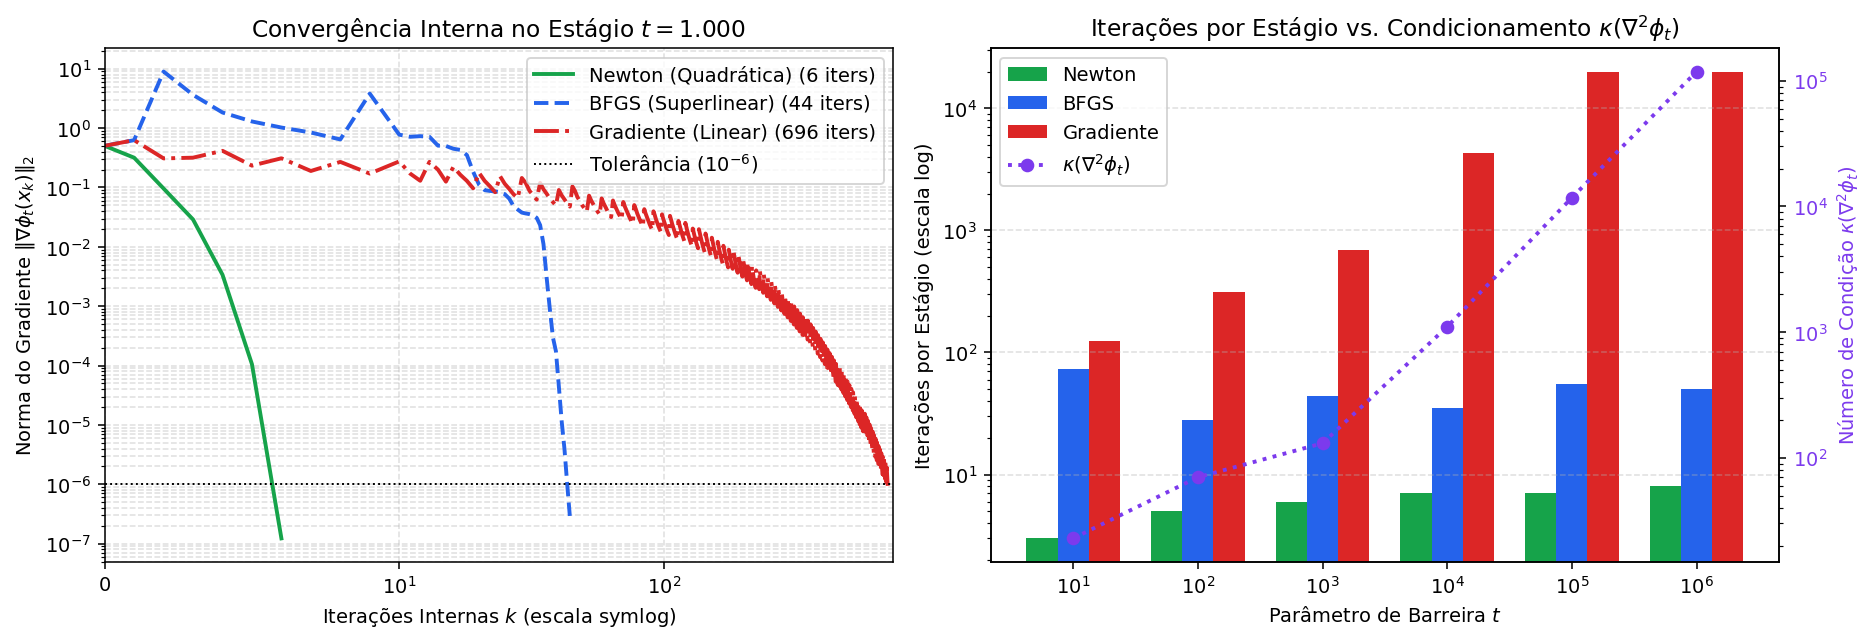

,Barreira t,Gap N/t,Cond κ(∇²φ_t),Newton,BFGS,Gradiente
Estágio,,,,,,
1,10^1,2.0e+00,22.8,3,73,125
2,10^2,2.0e-01,70.0,5,28,314
3,10^3,2.0e-02,130.5,6,44,696
4,10^4,2.0e-03,1103.3,7,35,"4,307"
5,10^5,2.0e-04,11741.8,7,55,"20,000 (limite)"
6,10^6,2.0e-05,118397.9,8,50,"20,000 (limite)"


In [4]:
from src.barrier_solvers import barrier_method, solve_scipy_reference

res_newton  = barrier_method(mu_a, S_a, gamma=5.0, method="newton")
res_bfgs    = barrier_method(mu_a, S_a, gamma=5.0, method="bfgs")
res_grad    = barrier_method(mu_a, S_a, gamma=5.0, method="grad")
res_climate = barrier_method(mu_b, S_b, gamma=5.0, method="newton")
w_scipy     = solve_scipy_reference(mu_a, S_a, gamma=5.0)

print("=== Validação KKT e SciPy (SLSQP) ===")
print(f"max |w_newton - w_scipy|                  : {np.max(np.abs(res_newton.weights - w_scipy)):.2e}")
print(f"Resíduo de estacionariedade KKT (inf)     : {res_newton.stationarity_residual:.2e}")
print(f"Folga complementar max_i |lambda_i * w_i| : {res_newton.comp_slackness_max:.2e} (= 1/t = 10^-6)")
print(f"Total de iterações (6 estágios)           : Newton={sum(res_newton.stage_iters)} | BFGS={sum(res_bfgs.stage_iters)} | Gradiente={sum(res_grad.stage_iters):,d}+")

# Tabela de convergência e condicionamento
conv_df = pd.DataFrame([
    {
        "Estágio": i + 1,
        "Barreira t": f"10^{i+1}",
        "Gap N/t": f"{res_newton.stages[i].duality_gap_bound:.1e}",
        "Cond κ(∇²φ_t)": round(res_newton.stages[i].hess_cond, 1),
        "Newton": res_newton.stage_iters[i],
        "BFGS": res_bfgs.stage_iters[i],
        "Gradiente": f"{res_grad.stage_iters[i]:,d}" + (" (limite)" if res_grad.stage_iters[i] >= 20000 else ""),
    }
    for i in range(len(res_newton.stages))
]).set_index("Estágio")

# Gráfico de convergência (t = 1000) e condicionamento
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.7))
stage_idx = 2  # t = 1,000
ax = axes[0]
for res, label, color, ls in [
    (res_newton, "Newton (Quadrática)", "#16a34a", "-"),
    (res_bfgs, "BFGS (Superlinear)", "#2563eb", "--"),
    (res_grad, "Gradiente (Linear)", "#dc2626", "-."),
]:
    gh = res.stages[stage_idx].grad_norm_history
    ax.semilogy(np.arange(len(gh)), gh, label=f"{label} ({len(gh)-1} iters)", color=color, linestyle=ls, linewidth=2.0)
ax.axhline(1e-6, color="black", linestyle=":", linewidth=1.0, label="Tolerância ($10^{-6}$)")
ax.set_xscale("symlog", linthresh=10)
ax.set_xlim(left=0)
ax.set_xlabel("Iterações Internas $k$ (escala symlog)")
ax.set_ylabel("Norma do Gradiente $\\|\\nabla \\phi_t(x_k)\\|_2$")
ax.set_title("Convergência Interna no Estágio $t = 1.000$")
ax.grid(True, which="both", linestyle="--", alpha=0.4)
ax.legend(loc="upper right")

ax2 = axes[1]
x_idx = np.arange(len(res_newton.stages))
w_bar = 0.25
ax2.bar(x_idx - w_bar, res_newton.stage_iters, width=w_bar, label="Newton", color="#16a34a")
ax2.bar(x_idx, res_bfgs.stage_iters, width=w_bar, label="BFGS", color="#2563eb")
ax2.bar(x_idx + w_bar, res_grad.stage_iters, width=w_bar, label="Gradiente", color="#dc2626")
ax2.set_yscale("log")
ax2.set_xticks(x_idx)
ax2.set_xticklabels([f"$10^{i+1}$" for i in range(len(x_idx))])
ax2.set_xlabel("Parâmetro de Barreira $t$")
ax2.set_ylabel("Iterações por Estágio (escala log)")
ax2.set_title("Iterações por Estágio vs. Condicionamento $\\kappa(\\nabla^2 \\phi_t)$")
ax2.grid(True, axis="y", linestyle="--", alpha=0.4)

ax2_t = ax2.twinx()
ax2_t.plot(x_idx, [s.hess_cond for s in res_newton.stages], color="#7c3aed", marker="o", linewidth=2.0, linestyle=":", label="$\\kappa(\\nabla^2 \\phi_t)$")
ax2_t.set_yscale("log")
ax2_t.set_ylabel("Número de Condição $\\kappa(\\nabla^2 \\phi_t)$", color="#7c3aed")
ax2_t.tick_params(axis="y", labelcolor="#7c3aed")
l1, lb1 = ax2.get_legend_handles_labels()
l2, lb2 = ax2_t.get_legend_handles_labels()
ax2.legend(l1 + l2, lb1 + lb2, loc="upper left")
fig.tight_layout()
plt.show()

conv_df

---

## 5. Solução Primal-Dual KKT & Análise de Sensibilidade (Slide 11)

Abaixo vemos dois resultados diretos da teoria de otimalidade:
1. **Esquerda:** Sem $w \ge 0$, a solução fechada KKT vende 8 ativos a descoberto (`BEEF3` $-23{,}3\%$, `DXCO3` $-22{,}5\%$, etc.). Ao impor $w \ge 0$, o conjunto ativo muda por inteiro: a barreira zera **12 ativos** (incluindo `RAPT4`, que tinha $+27{,}5\%$ na solução fechada), deixando apenas **8 ativos positivos** ($> 0{,}5\%$, esparsidade natural via folga complementar).
2. **Direita (Sensibilidade a $p_t$):** Ao alterar os pesos dos cenários $p_t$ pelo kernel climático de 11 variáveis (sem mudar nada no algoritmo), o conjunto ativo KKT desloca-se para **6 ativos** (concentrando em `SLCE3`, `MTSA4`, `MRFG3`, `PTNT4`, `FHER3`).

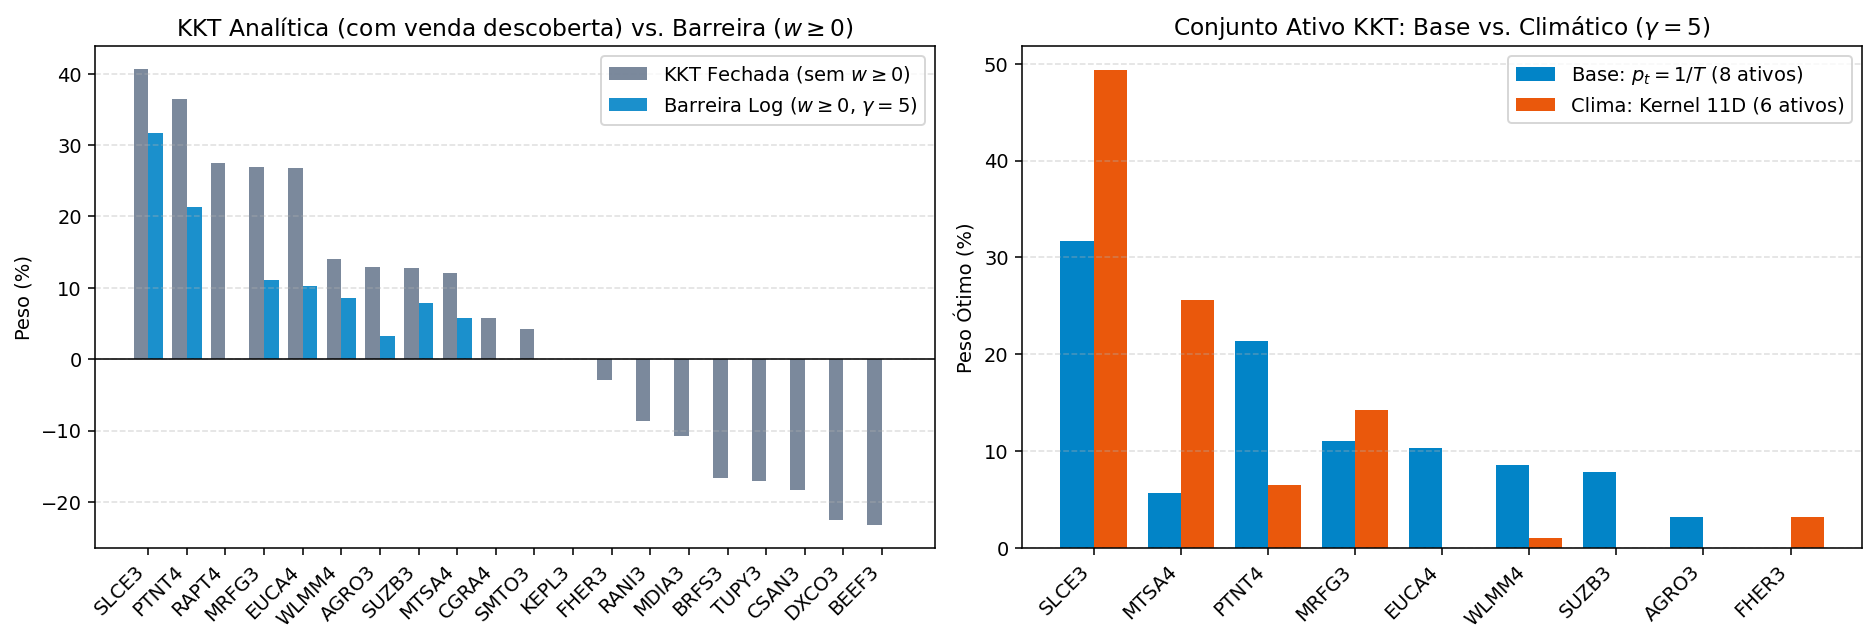

,KKT Irrestrito (%),Barreira Base w* (%),Dual λ_hat (Base),Barreira Clima w* (%)
Ativo,,,,
AGRO3,12.94,3.26,0.0000,0.00
BEEF3,-23.29,0.00,0.1778,0.00
BRFS3,-16.64,0.00,0.1916,0.00
CGRA4,5.82,0.02,0.0044,0.00
CSAN3,-18.35,0.00,0.1179,0.00
DXCO3,-22.50,0.00,0.0977,0.00
EUCA4,26.80,10.31,0.0000,0.01
FHER3,-2.96,0.00,0.0554,3.18
KEPL3,0.07,0.00,0.0640,0.00


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.7))
width = 0.38

ax = axes[0]
order = np.argsort(w_kkt)[::-1]
x_pos = np.arange(len(est.tickers))
ax.bar(x_pos - width/2, w_kkt[order]*100, width=width, label="KKT Fechada (sem $w \\geq 0$)", color="#64748b", alpha=0.85)
ax.bar(x_pos + width/2, res_newton.weights[order]*100, width=width, label="Barreira Log ($w \\geq 0$, $\\gamma=5$)", color="#0284c7", alpha=0.9)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x_pos)
ax.set_xticklabels([est.tickers[i] for i in order], rotation=45, ha="right")
ax.set_ylabel("Peso (%)")
ax.set_title("KKT Analítica (com venda descoberta) vs. Barreira ($w \\geq 0$)")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend(loc="upper right")

ax2 = axes[1]
active_idx = sorted(
    [i for i in range(len(est.tickers)) if res_newton.weights[i] > 1e-3 or res_climate.weights[i] > 1e-3],
    key=lambda i: max(res_newton.weights[i], res_climate.weights[i]),
    reverse=True,
)
x2 = np.arange(len(active_idx))
ax2.bar(x2 - width/2, res_newton.weights[active_idx]*100, width=width, label=f"Base: $p_t=1/T$ ({int((res_newton.weights>5e-3).sum())} ativos)", color="#0284c7")
ax2.bar(x2 + width/2, res_climate.weights[active_idx]*100, width=width, label=f"Clima: Kernel 11D ({int((res_climate.weights>5e-3).sum())} ativos)", color="#ea580c")
ax2.set_xticks(x2)
ax2.set_xticklabels([est.tickers[i] for i in active_idx], rotation=45, ha="right")
ax2.set_ylabel("Peso Ótimo (%)")
ax2.set_title("Conjunto Ativo KKT: Base vs. Climático ($\\gamma=5$)")
ax2.grid(axis="y", linestyle="--", alpha=0.4)
ax2.legend(loc="upper right")
fig.tight_layout()
plt.show()

kkt_df = pd.DataFrame({
    "Ativo": est.tickers,
    "KKT Irrestrito (%)": np.round(w_kkt * 100, 2),
    "Barreira Base w* (%)": np.round(res_newton.weights * 100, 2),
    "Dual λ_hat (Base)": np.round(res_newton.lambda_dual, 4),
    "Barreira Clima w* (%)": np.round(res_climate.weights * 100, 2),
}).set_index("Ativo")
kkt_df

---

## 6. Extra: Sensibilidade Paramétrica em $\gamma$ (Fronteira) & Validação Out-of-Sample (2025)

Como extensão paramétrica de Markowitz (Slide Extra / Resultados):
1. **Fronteira Eficiente:** Variamos $\gamma \in [0{,}5,\; 50]$ e traçamos o conjunto ótimo de Pareto $(\sqrt{w^*(\gamma)^\top \Sigma w^*(\gamma)},\; \mu^\top w^*(\gamma))$.
2. **Backtest 2025 (12 meses buy-and-hold):** Aplicamos os pesos ótimos $w^*$ de dez/2024 diretamente nos retornos realizados de 2025 (sem rebalanceamento), comparando com o ETF Agro (`AGRI11`) e o **CDI**.

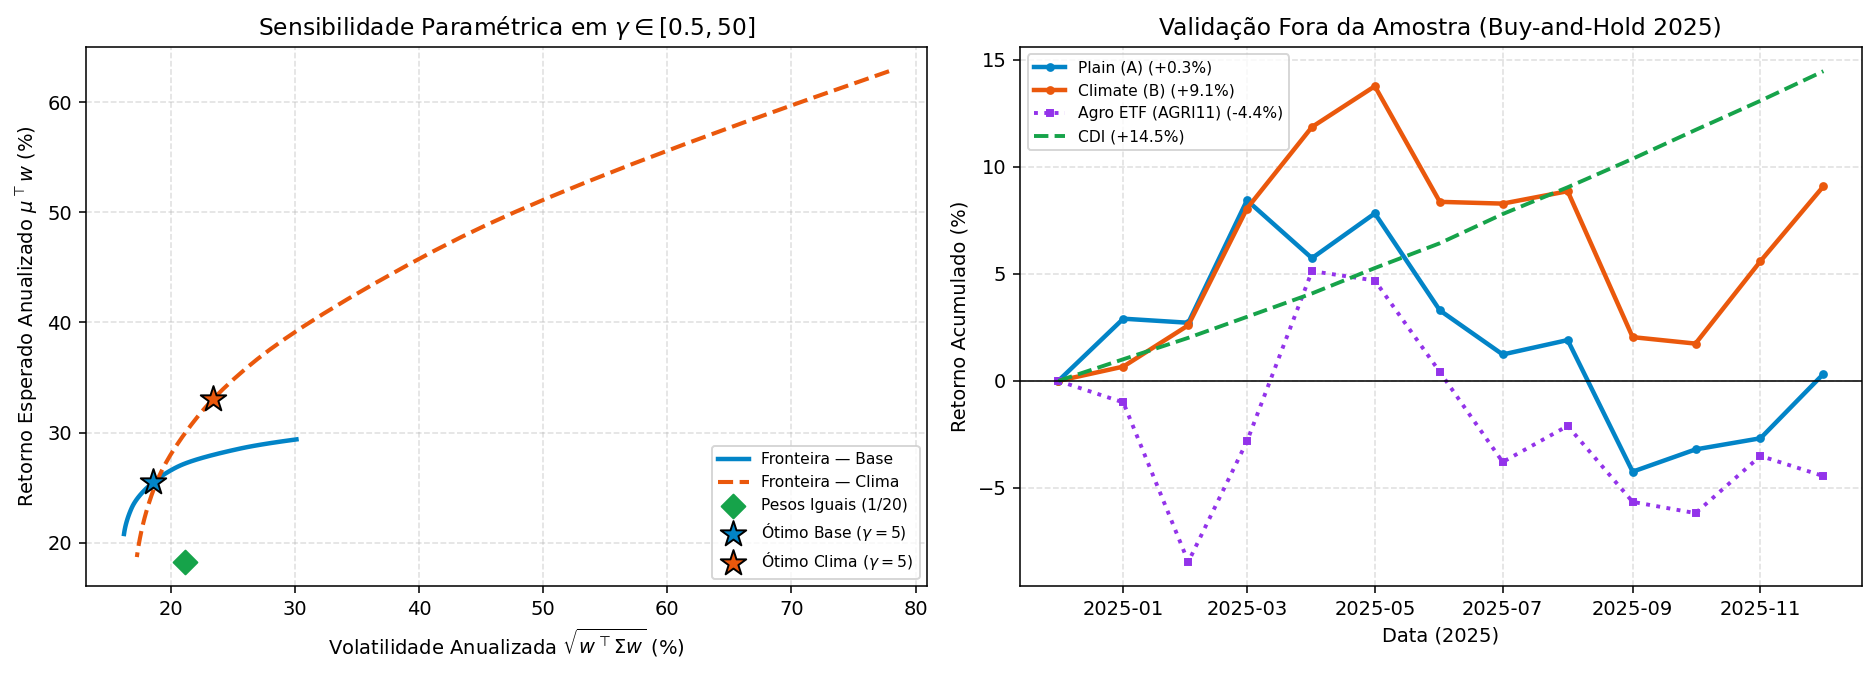

,Retorno Total (%),Volatilidade Anual (%),Max Drawdown (%),Sharpe vs. CDI
Estratégia,,,,
Plain (A),0.32,11.39,-11.68,-1.11
Climate (B),9.08,11.80,-10.56,-0.36
Agro ETF (AGRI11),-4.44,15.53,-10.75,-1.10
CDI,14.46,0.37,0.00,0.00


In [6]:
from src.barrier_solvers import compute_efficient_frontier
from src.run_experiments import load_test_year_returns_and_cdi
from src.backtest import run_backtest_comparison

front_a = compute_efficient_frontier(mu_a, S_a)
front_b = compute_efficient_frontier(mu_b, S_b)

R_test, cdi_test = load_test_year_returns_and_cdi()
bt_results = run_backtest_comparison(
    R_test=R_test,
    tickers_20=est.tickers,
    w_plain_20=res_newton.weights,
    w_climate_20=res_climate.weights,
    cdi_test=cdi_test,
)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.9))

# Left: Efficient Frontier (parametric sweep in gamma)
ax = axes[0]
ax.plot(front_a["volatility"]*100, front_a["expected_return"]*100, color="#0284c7", linewidth=2.3, label="Fronteira — Base")
ax.plot(front_b["volatility"]*100, front_b["expected_return"]*100, color="#ea580c", linewidth=2.1, linestyle="--", label="Fronteira — Clima")
w_eq = np.full(len(mu_a), 1.0 / len(mu_a))
ax.scatter([np.sqrt(w_eq @ S_a @ w_eq)*100], [mu_a @ w_eq * 100], color="#16a34a", marker="D", s=75, zorder=5, label="Pesos Iguais (1/20)")
ax.scatter([res_newton.volatility*100], [res_newton.exp_return*100], color="#0284c7", marker="*", s=190, edgecolor="black", zorder=6, label="Ótimo Base ($\\gamma=5$)")
ax.scatter([res_climate.volatility*100], [res_climate.exp_return*100], color="#ea580c", marker="*", s=190, edgecolor="black", zorder=6, label="Ótimo Clima ($\\gamma=5$)")
ax.set_xlabel("Volatilidade Anualizada $\\sqrt{w^\\top \\Sigma w}$ (%)")
ax.set_ylabel("Retorno Esperado Anualizado $\\mu^\\top w$ (%)")
ax.set_title("Sensibilidade Paramétrica em $\\gamma \\in [0.5, 50]$")
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(loc="lower right", fontsize=8)

# Right: 2025 Backtest
ax2 = axes[1]
styles = [
    ("Plain (A)", "#0284c7", "-", 2.3, "o"),
    ("Climate (B)", "#ea580c", "-", 2.3, "o"),
    ("Agro ETF (AGRI11)", "#9333ea", ":", 2.0, "s"),
    ("CDI", "#16a34a", "--", 2.0, None),
]
for name, color, ls, lw, mk in styles:
    if name in bt_results:
        m = bt_results[name]
        cum_pct = (m.wealth_index - 1.0) * 100.0
        ax2.plot(cum_pct.index, cum_pct.values, label=f"{name} ({m.total_return*100:+.1f}%)", color=color, linestyle=ls, linewidth=lw, marker=mk, markersize=3.5 if mk else 0)
ax2.axhline(0.0, color="black", linewidth=0.8)
ax2.set_xlabel("Data (2025)")
ax2.set_ylabel("Retorno Acumulado (%)")
ax2.set_title("Validação Fora da Amostra (Buy-and-Hold 2025)")
ax2.grid(True, linestyle="--", alpha=0.4)
ax2.legend(loc="upper left", fontsize=8)

fig.tight_layout()
plt.show()

pd.DataFrame([
    {
        "Estratégia": name,
        "Retorno Total (%)": round(m.total_return * 100, 2),
        "Volatilidade Anual (%)": round(m.annualized_volatility * 100, 2),
        "Max Drawdown (%)": round(m.max_drawdown * 100, 2),
        "Sharpe vs. CDI": round(m.sharpe_vs_cdi, 2),
    }
    for name, m in bt_results.items()
]).set_index("Estratégia")